[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/langchain-ai/langchain-academy/blob/main/module-1/chain.ipynb) [![Open in LangChain Academy](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66e9eba12c7b7688aa3dbb5e_LCA-badge-green.svg)](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/58238466-lesson-4-chain)

# Cadena

## Repaso

Construimos un grafo simple con nodos, aristas normales y aristas condicionales.

## Objetivos

Ahora vamos a construir una cadena simple que combina 4 conceptos.

* Usar [mensajes de chat](https://docs.langchain.com/oss/python/langchain/messages) como estado del grafo
* Usar [modelos de chat](https://docs.langchain.com/oss/python/integrations/chat) en los nodos del grafo
* [Enlazar herramientas](https://docs.langchain.com/oss/python/langchain/models#tool-calling) (*bind tools*) a nuestro modelo de chat
* [Ejecutar llamadas a herramientas](https://docs.langchain.com/oss/python/langchain/models#tool-execution-loop) en los nodos del grafo

![Captura de pantalla del esquema de la cadena](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbab08dd607b08df5e1101_chain1.png)

In [ ]:
%%capture --no-stderr
%pip install --quiet -U langchain_openai langchain_core langgraph

## Mensajes

Los modelos de chat pueden usar [mensajes](https://docs.langchain.com/oss/python/langchain/messages), que capturan los distintos roles dentro de una conversación.

LangChain admite varios tipos de mensajes, entre ellos `HumanMessage`, `AIMessage`, `SystemMessage` y `ToolMessage`.

Representan, respectivamente, un mensaje del usuario, uno del modelo de chat, uno para indicarle al modelo de chat cómo comportarse y uno que viene de una llamada a herramienta.

Creemos una lista de mensajes.

A cada mensaje se le pueden dar algunos datos:

* `content`: el contenido del mensaje
* `name`: opcionalmente, el autor del mensaje
* `response_metadata`: opcionalmente, un diccionario con metadatos (por ejemplo, el proveedor del modelo suele completarlo en los `AIMessage`)

In [1]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage

mensajes = [AIMessage(content=f"Entonces me dijiste que estabas investigando mamíferos marinos, ¿cierto?", name="Modelo")]
mensajes.append(HumanMessage(content=f"Sí, así es.",name="Lance"))
mensajes.append(AIMessage(content=f"Genial, ¿sobre qué te gustaría aprender?", name="Modelo"))
mensajes.append(HumanMessage(content=f"Quiero saber cuál es el mejor lugar para ver orcas en Estados Unidos.", name="Lance"))

for m in mensajes:
    m.pretty_print()

================================== Ai Message ==================================
Name: Model

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Lance

Yes, that's right.
================================== Ai Message ==================================
Name: Model

Great, what would you like to learn about.
================================ Human Message =================================
Name: Lance

I want to learn about the best place to see Orcas in the US.


## Modelos de chat

Los modelos de chat reciben una secuencia de mensajes como entrada y admiten los tipos de mensajes que vimos arriba.

¡Hay [muchos](https://docs.langchain.com/oss/python/integrations/chat) para elegir! Trabajemos con OpenAI.

Revisemos que tu `OPENAI_API_KEY` esté definida. Si no lo está, se te pedirá que la ingreses.

In [2]:
import os, getpass

def _definir_variable(variable: str):
    if not os.environ.get(variable):
        os.environ[variable] = getpass.getpass(f"{variable}: ")

_definir_variable("OPENAI_API_KEY")

Podemos cargar un modelo de chat e invocarlo con nuestra lista de mensajes.

Vemos que el resultado es un `AIMessage` con `response_metadata` específicos.

In [2]:
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o")
resultado = llm.invoke(mensajes)
type(resultado)

langchain_core.messages.ai.AIMessage

In [3]:
resultado

AIMessage(content='One of the best places to see orcas in the United States is the Pacific Northwest, particularly around the San Juan Islands in Washington State. Here are some details:\n\n1. **San Juan Islands, Washington**: These islands are a renowned spot for whale watching, with orcas frequently spotted between late spring and early fall. The waters around the San Juan Islands are home to both resident and transient orca pods, making it an excellent location for sightings.\n\n2. **Puget Sound, Washington**: This area, including places like Seattle and the surrounding waters, offers additional opportunities to see orcas, particularly the Southern Resident killer whale population.\n\n3. **Olympic National Park, Washington**: The coastal areas of the park provide a stunning backdrop for spotting orcas, especially during their migration periods.\n\nWhen planning a trip for whale watching, consider peak seasons for orca activity and book tours with reputable operators who adhere to re

In [4]:
resultado.response_metadata

{'token_usage': {'completion_tokens': 228,
  'prompt_tokens': 67,
  'total_tokens': 295,
  'completion_tokens_details': {'accepted_prediction_tokens': 0,
   'audio_tokens': 0,
   'reasoning_tokens': 0,
   'rejected_prediction_tokens': 0},
  'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}},
 'model_name': 'gpt-4o-2024-08-06',
 'system_fingerprint': 'fp_50cad350e4',
 'finish_reason': 'stop',
 'logprobs': None}

## Herramientas

Las herramientas sirven cuando quieres que un modelo interactúe con sistemas externos.

Los sistemas externos (por ejemplo, las API) suelen requerir un esquema de entrada o un payload específico, en vez de lenguaje natural.

Cuando enlazamos una API como herramienta, por ejemplo, le damos al modelo información sobre el esquema de entrada que necesita.

El modelo decide llamar a una herramienta según la entrada en lenguaje natural del usuario.

Y devuelve una salida que respeta el esquema de la herramienta.

[Muchos proveedores de LLM admiten la llamada a herramientas](https://docs.langchain.com/oss/python/integrations/chat), y la [interfaz de llamada a herramientas](https://blog.langchain.com/improving-core-tool-interfaces-and-docs-in-langchain/) de LangChain es simple.

Basta con pasar cualquier `function` de Python a `ChatModel.bind_tools(function)`.

![Captura de pantalla del esquema de llamada a herramientas](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbab08dc1c17a7a57f9960_chain2.png)

Veamos un ejemplo simple de llamada a herramienta.

La función `multiplicar` es nuestra herramienta.

In [5]:
def multiplicar(a: int, b: int) -> int:
    """Multiplica a y b.

    Args:
        a: primer entero
        b: segundo entero
    """
    return a * b

llm_con_herramientas = llm.bind_tools([multiplicar])

Si le pasamos una entrada, por ejemplo `"¿Cuánto es 2 multiplicado por 3?"`, vemos que devuelve una llamada a herramienta.

La llamada a herramienta trae argumentos que coinciden con el esquema de entrada de nuestra función, junto con el nombre de la función a la que hay que llamar.

```
{'arguments': '{"a":2,"b":3}', 'name': 'multiplicar'}
```

In [8]:
llamada_herramienta = llm_con_herramientas.invoke([HumanMessage(content=f"¿Cuánto es 2 multiplicado por 3?", name="Lance")])

In [9]:
llamada_herramienta.tool_calls

[{'name': 'multiply',
  'args': {'a': 2, 'b': 3},
  'id': 'call_lBBBNo5oYpHGRqwxNaNRbsiT',
  'type': 'tool_call'}]

## Usar mensajes como estado

Con estas bases, ya podemos usar [mensajes](https://docs.langchain.com/oss/python/langchain/overview#messages) en el estado de nuestro grafo.

Definamos nuestro estado, `MessagesState`, como un `TypedDict` con una sola clave: `messages`.

`messages` es simplemente una lista de mensajes, como la que definimos arriba (por ejemplo, `HumanMessage`, etc.).

In [1]:
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage

class MessagesState(TypedDict):
    messages: list[AnyMessage]

## Reducers

¡Ahora tenemos un problema menor!

Como vimos, cada nodo devolverá un nuevo valor para la clave `messages` del estado.

¡Pero ese nuevo valor reemplazará el valor anterior de `messages`!

A medida que el grafo se ejecuta, queremos **agregar** mensajes a la clave `messages` del estado.

Para resolverlo podemos usar [funciones *reducer*](https://docs.langchain.com/oss/python/langgraph/graph-api#reducers).

Los *reducers* especifican cómo se aplican las actualizaciones del estado.

Si no se especifica ninguna función *reducer*, se asume que las actualizaciones de la clave *reemplazan* el valor, como vimos antes.

Pero, para agregar mensajes, podemos usar el *reducer* predefinido `add_messages`.

Así nos aseguramos de que los mensajes nuevos se agreguen a la lista de mensajes existente.

Solo tenemos que anotar nuestra clave `messages` con la función *reducer* `add_messages` como metadato.

In [10]:
from typing import Annotated
from langgraph.graph.message import add_messages

class MessagesState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

Como es tan común tener una lista de mensajes en el estado del grafo, LangGraph trae un [`MessagesState`](https://docs.langchain.com/oss/python/langgraph/graph-api#messagesstate) predefinido.

`MessagesState` se define así:

* Con una única clave `messages` predefinida
* Esta clave es una lista de objetos `AnyMessage`
* Usa el *reducer* `add_messages`

Normalmente usaremos `MessagesState`, porque es menos verboso que definir un `TypedDict` propio como el de arriba.

In [13]:
from langgraph.graph import MessagesState

class MessagesState(MessagesState):
    # Agrega aquí las claves que necesites además de messages, que ya viene predefinida
    pass

Para profundizar un poco, veamos cómo funciona el *reducer* `add_messages` por sí solo.

In [12]:
# Estado inicial
mensajes_iniciales = [AIMessage(content="¡Hola! ¿En qué puedo ayudarte?", name="Modelo"),
                      HumanMessage(content="Busco información sobre biología marina.", name="Lance")
                     ]

# Mensaje nuevo que se agregará
mensaje_nuevo = AIMessage(content="Claro, puedo ayudarte con eso. ¿Qué te interesa en particular?", name="Modelo")

# Prueba
add_messages(mensajes_iniciales , mensaje_nuevo)

[AIMessage(content='Hello! How can I assist you?', name='Model', id='cd566566-0f42-46a4-b374-fe4d4770ffa7'),
 HumanMessage(content="I'm looking for information on marine biology.", name='Lance', id='9b6c4ddb-9de3-4089-8d22-077f53e7e915'),
 AIMessage(content='Sure, I can help with that. What specifically are you interested in?', name='Model', id='74a549aa-8b8b-48d4-bdf1-12e98404e44e')]

## Nuestro grafo

Ahora usemos `MessagesState` con un grafo.

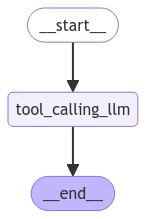

In [14]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# Nodo
def llamar_llm(estado: MessagesState):
    return {"messages": [llm_con_herramientas.invoke(estado["messages"])]}

# Construir el grafo
constructor = StateGraph(MessagesState)
constructor.add_node("llamar_llm", llamar_llm)
constructor.add_edge(START, "llamar_llm")
constructor.add_edge("llamar_llm", END)
grafo = constructor.compile()

# Visualizar
display(Image(grafo.get_graph().draw_mermaid_png()))

Si le pasamos `¡Hola!`, el LLM responde sin hacer ninguna llamada a herramienta.

In [15]:
mensajes = grafo.invoke({"messages": HumanMessage(content="¡Hola!")})
for m in mensajes['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello!
================================== Ai Message ==================================

Hi there! How can I assist you today?


El LLM decide usar una herramienta cuando determina que la entrada o la tarea requiere la funcionalidad que esa herramienta ofrece.

In [16]:
mensajes = grafo.invoke({"messages": HumanMessage(content="Multiplica 2 y 3")})
for m in mensajes['messages']:
    m.pretty_print()

================================ Human Message =================================

Multiply 2 and 3!
================================== Ai Message ==================================
Tool Calls:
  multiply (call_Er4gChFoSGzU7lsuaGzfSGTQ)
 Call ID: call_Er4gChFoSGzU7lsuaGzfSGTQ
  Args:
    a: 2
    b: 3
